# Importamos librerías

In [1]:
import tensorflow as tf
import pathlib
import os
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import keras

In [2]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import Dropout, BatchNormalization
from tensorflow.keras.initializers import HeNormal
from keras.regularizers import l1, l2

In [3]:
tf.test.is_gpu_available()

Instructions for updating:
Use `tf.config.list_physical_devices('GPU')` instead.


False

# Importamos los datos

In [4]:
path = '../../../data/clean/Campo 50 puntos'

## Datos de entrenamiento

### Datos

In [5]:
campvectrain = np.load(path + '/campvectrain.npy')

In [6]:
np.shape(campvectrain)

(7000, 2, 50, 50)

### Coeficientes

In [7]:
coefcampvectrain = np.load(path + '/coefcampvectrain.npy')

In [8]:
np.shape(coefcampvectrain)

(7000, 7)

## Datos de prueba

### Datos

In [9]:
campvectest = np.load(path + '/campvectest.npy')

In [10]:
np.shape(campvectest)

(1000, 2, 50, 50)

### Coeficientes

In [11]:
coefcampvectest = np.load(path + '/coefcampvectest.npy')

In [12]:
np.shape(coefcampvectest)

(1000, 7)

## Datos de validación

### Datos

In [13]:
campvecval = np.load(path + '/campvecval.npy')

In [14]:
np.shape(campvecval)

(2000, 2, 50, 50)

### Coeficienes

In [15]:
coefcampvecval = np.load(path + '/coefcampvecval.npy')

In [16]:
np.shape(coefcampvecval)

(2000, 7)

# Unimos coeficientes con los datos

In [17]:
train_dataset = tf.data.Dataset.from_tensor_slices((campvectrain, coefcampvectrain))
test_dataset = tf.data.Dataset.from_tensor_slices((campvectest, coefcampvectest))
val_dataset = tf.data.Dataset.from_tensor_slices((campvecval, coefcampvecval))

In [18]:
train_dataset

<TensorSliceDataset element_spec=(TensorSpec(shape=(2, 50, 50), dtype=tf.float64, name=None), TensorSpec(shape=(7,), dtype=tf.int32, name=None))>

# Mezclar y procesar por lotes los conjuntos de datos

In [19]:
BATCH_SIZE = 100
SHUFFLE_BUFFER_SIZE = 100

train_dataset = train_dataset.shuffle(SHUFFLE_BUFFER_SIZE).batch(BATCH_SIZE)
test_dataset = test_dataset.batch(BATCH_SIZE)
val_dataset = val_dataset.batch(BATCH_SIZE)

# Creación del modelo

In [20]:
def custom_activation(x):
    return 10 * tf.nn.sigmoid(x)

In [21]:
def total_mae_loss(y_true, y_pred):
    total_loss = 0
    num_parameters = 7
    for i in range(num_parameters):
        total_loss += tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])
    tf.print(y_true, summarize = -1)
    tf.print(y_pred, summarize = -1)
    return total_loss / num_parameters

In [22]:
coeficientesnombres = ('a_1', 'a_2', 'b_1', 'b_2', 'd_1', 'd_2', 'n')

def mse_component(i):
    def mse_i(y_true, y_pred):
        return tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])

    mse_i.__name__ = coeficientesnombres[i]
    return mse_i

def mean_metric(y_true, y_pred):
    total_loss = 0
    for i in range(7):
        total_loss += mse_component(i)(y_true, y_pred)
    sum_of_true_coefficients = tf.reduce_sum(y_true, axis=-1)
    return total_loss / sum_of_true_coefficients

metrics = [mse_component(i) for i in range(7)] + [mean_metric]

In [23]:
from keras.optimizers import Adam
optimizer = Adam(learning_rate=0.001,clipvalue=100.0)

In [24]:
def total_mae_loss(y_true, y_pred):
    total_loss = 0
    num_parameters = 7
    for i in range(num_parameters):
        total_loss += tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])
    tf.print(y_true, summarize = -1)
    tf.print(y_pred, summarize = -1)
    return total_loss / num_parameters

In [25]:
def adaptive_learning_rate(epoch):
    initial_lr = 0.001
    final_lr = 0.000001  # Updated final learning rate
    start_decay_epoch = 200
    end_decay_epoch = 1000
    
    if epoch < start_decay_epoch:
        return initial_lr
    elif epoch >= start_decay_epoch and epoch <= end_decay_epoch:
        lr_range = initial_lr - final_lr
        decay_epochs = end_decay_epoch - start_decay_epoch
        decay_per_epoch = lr_range / decay_epochs
        return initial_lr - (epoch - start_decay_epoch) * decay_per_epoch
    else:
        return final_lr
    
early_stop = tf.keras.callbacks.EarlyStopping( monitor = 'val_loss', patience = 1000,verbose = 1, 
                                              restore_best_weights = True)
reduce_lr = tf.keras.callbacks.LearningRateScheduler(adaptive_learning_rate)

In [ ]:
import optuna
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
from tensorflow.keras.regularizers import l1, l2
from tensorflow.keras.layers import BatchNormalization
import optuna

def objective(trial):
    model = Sequential()
    
    model.add(Flatten(input_shape=(2, 50, 50)))  # Tus dimensiones de entrada
    n_dense_layers = trial.suggest_int("n_dense_layers", 1, 8)
    
    for i in range(n_dense_layers):
        add_batch_norm = trial.suggest_categorical(f"add_batch_norm_before_dense_{i+1}", [True, False])
        if add_batch_norm:
            model.add(BatchNormalization())
        num_units = trial.suggest_int(f"num_units_{i+1}", 16, 128)
        activation = trial.suggest_categorical(f"dense_activation_{i+1}", ['relu', 'tanh', 'sigmoid'])
        kernel_initializer = trial.suggest_categorical(f"dense_kernel_initializer_{i+1}", ['HeNormal', 'glorot_uniform', 'random_normal'])
        kernel_regularizer = trial.suggest_categorical(f"dense_kernel_regularizer_{i+1}", ['l1', 'l2'])

        regularizer = None
        if kernel_regularizer == 'l1':
            regularizer = l1(0.001)
        elif kernel_regularizer == 'l2':
            regularizer = l2(0.001)

        model.add(Dense(num_units, activation=activation, kernel_initializer=kernel_initializer, kernel_regularizer=regularizer))
    
        # Decide si agregar una capa de Dropout después de esta capa densa
        add_dropout = trial.suggest_categorical(f"add_dropout_after_dense_{i+1}", [True, False])
        if add_dropout:
            dropout_rate = trial.suggest_float(f"dropout_rate_after_dense_{i+1}", 0.1, 0.5)
            model.add(Dropout(dropout_rate))
            
    model.add(Dense(7, activation=custom_activation))  # Asumiendo que tienes una función 'custom_activation'
    
    optimizer = Adam(learning_rate=0.001, clipvalue=100.0)
  
    model.compile(optimizer=optimizer, loss= 'mean_squared_error', metrics=metrics)
    
    history = model.fit(
        train_dataset, 
        validation_data=val_dataset, 
        epochs=20,  
        callbacks=[reduce_lr, early_stop]
    )
    
    val_mean_metric = history.history['val_mean_metric'][-1]
    
    return val_mean_metric

study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=300)

print(f'Número de trials finalizados: {len(study.trials)}')
print(f'Mejor trial:')
trial = study.best_trial

print(f'  Valor: {trial.value}')
print('  Parámetros: ')
for key, value in trial.params.items():
    print(f'    {key}: {value}')

C:\Users\rafae\anaconda3\envs\tfgpu\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2023-10-24 08:39:21,427] A new study created in memory with name: no-name-7ce23a02-ac7d-4fe8-98d6-74dafdb835c1


Epoch 1/20
70/70 [==============================] - 2s 17ms/step - loss: 15.9184 - a_1: 2.5714 - a_2: 2.5989 - b_1: 2.8953 - b_2: 3.0192 - d_1: 2.3171 - d_2: 2.3778 - n: 1.9825 - mean_metric: 0.5548 - val_loss: 11.5236 - val_a_1: 2.5014 - val_a_2: 2.4765 - val_b_1: 2.6577 - val_b_2: 2.7377 - val_d_1: 2.1504 - val_d_2: 2.1255 - val_n: 1.2265 - val_mean_metric: 0.4926 - lr: 0.0010
Epoch 2/20
70/70 [==============================] - 1s 13ms/step - loss: 11.2454 - a_1: 2.5496 - a_2: 2.5548 - b_1: 2.7728 - b_2: 2.7774 - d_1: 1.8491 - d_2: 1.9757 - n: 1.3533 - mean_metric: 0.4945 - val_loss: 10.0629 - val_a_1: 2.5005 - val_a_2: 2.4747 - val_b_1: 2.6576 - val_b_2: 2.7283 - val_d_1: 1.8919 - val_d_2: 1.8753 - val_n: 1.2403 - val_mean_metric: 0.4769 - lr: 0.0010
Epoch 3/20
70/70 [==============================] - 1s 13ms/step - loss: 10.4664 - a_1: 2.5534 - a_2: 2.5696 - b_1: 2.7851 - b_2: 2.7829 - d_1: 1.8424 - d_2: 1.8662 - n: 1.3447 - mean_metric: 0.4918 - val_loss: 9.3136 - val_a_1: 2.4965 

[I 2023-10-24 08:39:41,332] Trial 0 finished with value: 0.45423683524131775 and parameters: {'n_dense_layers': 7, 'add_batch_norm_before_dense_1': False, 'num_units_1': 112, 'dense_activation_1': 'tanh', 'dense_kernel_initializer_1': 'HeNormal', 'dense_kernel_regularizer_1': 'l1', 'add_dropout_after_dense_1': True, 'dropout_rate_after_dense_1': 0.4891129326291215, 'add_batch_norm_before_dense_2': True, 'num_units_2': 88, 'dense_activation_2': 'tanh', 'dense_kernel_initializer_2': 'random_normal', 'dense_kernel_regularizer_2': 'l2', 'add_dropout_after_dense_2': False, 'add_batch_norm_before_dense_3': False, 'num_units_3': 26, 'dense_activation_3': 'relu', 'dense_kernel_initializer_3': 'HeNormal', 'dense_kernel_regularizer_3': 'l2', 'add_dropout_after_dense_3': True, 'dropout_rate_after_dense_3': 0.32895187658358604, 'add_batch_norm_before_dense_4': False, 'num_units_4': 105, 'dense_activation_4': 'sigmoid', 'dense_kernel_initializer_4': 'HeNormal', 'dense_kernel_regularizer_4': 'l1', '

Epoch 1/20
70/70 [==============================] - 2s 16ms/step - loss: 11.0671 - a_1: 2.8207 - a_2: 2.8226 - b_1: 2.9835 - b_2: 2.9734 - d_1: 1.7368 - d_2: 1.5160 - n: 1.9715 - mean_metric: 0.5255 - val_loss: 8.5831 - val_a_1: 2.4968 - val_a_2: 2.4690 - val_b_1: 2.6428 - val_b_2: 2.7327 - val_d_1: 1.8159 - val_d_2: 1.8715 - val_n: 1.2336 - val_mean_metric: 0.4736 - lr: 0.0010
Epoch 2/20
70/70 [==============================] - 1s 13ms/step - loss: 8.8650 - a_1: 2.6348 - a_2: 2.6511 - b_1: 2.8009 - b_2: 2.7565 - d_1: 1.1778 - d_2: 1.1269 - n: 1.4938 - mean_metric: 0.4574 - val_loss: 8.2267 - val_a_1: 2.4997 - val_a_2: 2.4701 - val_b_1: 2.5974 - val_b_2: 2.6907 - val_d_1: 1.6564 - val_d_2: 1.6428 - val_n: 1.2842 - val_mean_metric: 0.4605 - lr: 0.0010
Epoch 3/20
70/70 [==============================] - 1s 13ms/step - loss: 7.7862 - a_1: 2.5984 - a_2: 2.6016 - b_1: 2.4495 - b_2: 2.1414 - d_1: 1.1627 - d_2: 1.0589 - n: 1.4181 - mean_metric: 0.4195 - val_loss: 7.6637 - val_a_1: 2.4905 - va

[I 2023-10-24 08:40:00,422] Trial 1 finished with value: 0.2353605479001999 and parameters: {'n_dense_layers': 7, 'add_batch_norm_before_dense_1': False, 'num_units_1': 33, 'dense_activation_1': 'relu', 'dense_kernel_initializer_1': 'glorot_uniform', 'dense_kernel_regularizer_1': 'l2', 'add_dropout_after_dense_1': True, 'dropout_rate_after_dense_1': 0.13741629953881965, 'add_batch_norm_before_dense_2': True, 'num_units_2': 94, 'dense_activation_2': 'relu', 'dense_kernel_initializer_2': 'random_normal', 'dense_kernel_regularizer_2': 'l2', 'add_dropout_after_dense_2': False, 'add_batch_norm_before_dense_3': False, 'num_units_3': 104, 'dense_activation_3': 'relu', 'dense_kernel_initializer_3': 'HeNormal', 'dense_kernel_regularizer_3': 'l1', 'add_dropout_after_dense_3': True, 'dropout_rate_after_dense_3': 0.33613230830661667, 'add_batch_norm_before_dense_4': True, 'num_units_4': 118, 'dense_activation_4': 'relu', 'dense_kernel_initializer_4': 'glorot_uniform', 'dense_kernel_regularizer_4':

Epoch 1/20
70/70 [==============================] - 1s 12ms/step - loss: 6.1754 - a_1: 2.4872 - a_2: 2.4923 - b_1: 1.5779 - b_2: 1.6946 - d_1: 1.2636 - d_2: 1.2541 - n: 1.4035 - mean_metric: 0.3802 - val_loss: 6.9120 - val_a_1: 2.4213 - val_a_2: 2.4079 - val_b_1: 2.1965 - val_b_2: 1.9893 - val_d_1: 1.8615 - val_d_2: 1.6407 - val_n: 1.2536 - val_mean_metric: 0.4274 - lr: 0.0010
Epoch 2/20
70/70 [==============================] - 1s 9ms/step - loss: 4.6136 - a_1: 2.2778 - a_2: 2.1729 - b_1: 1.1104 - b_2: 1.0950 - d_1: 1.0071 - d_2: 0.9981 - n: 1.2694 - mean_metric: 0.3102 - val_loss: 4.0857 - val_a_1: 1.9727 - val_a_2: 1.4000 - val_b_1: 1.4123 - val_b_2: 1.2204 - val_d_1: 1.1375 - val_d_2: 1.0935 - val_n: 1.2549 - val_mean_metric: 0.2946 - lr: 0.0010
Epoch 3/20
70/70 [==============================] - 1s 9ms/step - loss: 3.6046 - a_1: 1.7049 - a_2: 1.3326 - b_1: 1.0957 - b_2: 1.0912 - d_1: 1.0057 - d_2: 1.0199 - n: 1.2631 - mean_metric: 0.2659 - val_loss: 2.9935 - val_a_1: 1.2034 - val_a

... (150 outputs left out)

[I 2023-10-24 09:00:34,448] Trial 77 finished with value: 0.2638636529445648 and parameters: {'n_dense_layers': 5, 'add_batch_norm_before_dense_1': True, 'num_units_1': 121, 'dense_activation_1': 'sigmoid', 'dense_kernel_initializer_1': 'random_normal', 'dense_kernel_regularizer_1': 'l1', 'add_dropout_after_dense_1': True, 'dropout_rate_after_dense_1': 0.25575827508379434, 'add_batch_norm_before_dense_2': True, 'num_units_2': 89, 'dense_activation_2': 'tanh', 'dense_kernel_initializer_2': 'random_normal', 'dense_kernel_regularizer_2': 'l1', 'add_dropout_after_dense_2': False, 'add_batch_norm_before_dense_3': True, 'num_units_3': 46, 'dense_activation_3': 'relu', 'dense_kernel_initializer_3': 'HeNormal', 'dense_kernel_regularizer_3': 'l2', 'add_dropout_after_dense_3': True, 'dropout_rate_after_dense_3': 0.22559271784365043, 'add_batch_norm_before_dense_4': False, 'num_units_4': 28, 'dense_activation_4': 'sigmoid', 'dense_kernel_initializer_4': 'random_normal', 'dense_kernel_regularizer_

Epoch 1/20
70/70 [==============================] - 1s 15ms/step - loss: 7.0404 - a_1: 2.6627 - a_2: 2.7615 - b_1: 1.7730 - b_2: 1.7076 - d_1: 1.4502 - d_2: 1.3939 - n: 2.3808 - mean_metric: 0.4414 - val_loss: 6.3323 - val_a_1: 1.8345 - val_a_2: 1.9820 - val_b_1: 2.4927 - val_b_2: 2.0705 - val_d_1: 2.1122 - val_d_2: 2.2813 - val_n: 1.7134 - val_mean_metric: 0.4495 - lr: 0.0010
Epoch 2/20
70/70 [==============================] - 1s 12ms/step - loss: 3.5980 - a_1: 1.6393 - a_2: 1.8003 - b_1: 1.2833 - b_2: 1.2697 - d_1: 1.1877 - d_2: 1.1960 - n: 1.7763 - mean_metric: 0.3171 - val_loss: 2.7822 - val_a_1: 1.3175 - val_a_2: 1.3183 - val_b_1: 1.2865 - val_b_2: 1.4454 - val_d_1: 1.1963 - val_d_2: 1.1799 - val_n: 1.4972 - val_mean_metric: 0.2867 - lr: 0.0010
Epoch 3/20
70/70 [==============================] - 1s 12ms/step - loss: 2.6149 - a_1: 1.3246 - a_2: 1.3526 - b_1: 1.2180 - b_2: 1.1526 - d_1: 1.0924 - d_2: 1.0840 - n: 1.4591 - mean_metric: 0.2712 - val_loss: 1.6257 - val_a_1: 1.0010 - val

[I 2023-10-24 09:00:52,446] Trial 78 finished with value: 0.1398998647928238 and parameters: {'n_dense_layers': 1, 'add_batch_norm_before_dense_1': True, 'num_units_1': 45, 'dense_activation_1': 'tanh', 'dense_kernel_initializer_1': 'HeNormal', 'dense_kernel_regularizer_1': 'l2', 'add_dropout_after_dense_1': True, 'dropout_rate_after_dense_1': 0.2698747616475247}. Best is trial 22 with value: 0.0718422532081604.


Epoch 1/20
70/70 [==============================] - 2s 17ms/step - loss: 9.2974 - a_1: 2.2116 - a_2: 2.5057 - b_1: 1.6001 - b_2: 1.5351 - d_1: 1.1052 - d_2: 1.0530 - n: 1.2618 - mean_metric: 0.3521 - val_loss: 5.7475 - val_a_1: 1.9572 - val_a_2: 1.9276 - val_b_1: 1.5737 - val_b_2: 1.9646 - val_d_1: 1.7341 - val_d_2: 1.5093 - val_n: 1.2141 - val_mean_metric: 0.3687 - lr: 0.0010
Epoch 2/20
70/70 [==============================] - 1s 15ms/step - loss: 2.7704 - a_1: 1.2420 - a_2: 1.2001 - b_1: 0.9956 - b_2: 0.9992 - d_1: 0.8914 - d_2: 0.8938 - n: 1.1956 - mean_metric: 0.2317 - val_loss: 2.6815 - val_a_1: 1.4361 - val_a_2: 1.4423 - val_b_1: 1.0884 - val_b_2: 1.2102 - val_d_1: 1.1323 - val_d_2: 0.9791 - val_n: 1.2032 - val_mean_metric: 0.2635 - lr: 0.0010
Epoch 3/20
70/70 [==============================] - 1s 15ms/step - loss: 2.0255 - a_1: 0.9956 - a_2: 1.0328 - b_1: 0.8966 - b_2: 0.9008 - d_1: 0.8385 - d_2: 0.8463 - n: 1.2014 - mean_metric: 0.2097 - val_loss: 1.8221 - val_a_1: 0.9949 - val

In [100]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.regularizers import l1, l2

# Initialize the model
model = Sequential()

model.add(Flatten(input_shape=(2,50,50)))
# Add Dense Layers
# Dense Layer 1
model.add(Dense(16, activation='relu', kernel_initializer='random_normal', kernel_regularizer=l1(0.001)))

# Dense Layer 2
model.add(Dense(68, activation='relu', kernel_initializer='random_normal', kernel_regularizer=l1(0.001)))

# Dense Layer 3
model.add(Dense(106, activation='relu', kernel_initializer='he_normal', kernel_regularizer=l1(0.001)))

# Dense Layer 4
model.add(Dense(124, activation='relu', kernel_initializer='random_normal', kernel_regularizer=l2(0.001)))
model.add(Dropout(0.157))  # Dropout after Dense Layer 4

model.add(Dense(7, activation=custom_activation))

# Show the model architecture
model.summary()


Model: "sequential_312"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten_312 (Flatten)       (None, 5000)              0         
                                                                 
 dense_1711 (Dense)          (None, 16)                80016     
                                                                 
 dense_1712 (Dense)          (None, 68)                1156      
                                                                 
 dense_1713 (Dense)          (None, 106)               7314      
                                                                 
 dense_1714 (Dense)          (None, 124)               13268     
                                                                 
 dropout_459 (Dropout)       (None, 124)               0         
                                                                 
 dense_1715 (Dense)          (None, 7)              

In [21]:
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(2,50,50)),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dense(50, activation='tanh',kernel_initializer=HeNormal(), kernel_regularizer=l1(0.001)),
    tf.keras.layers.Dense(50, activation='tanh',kernel_initializer=HeNormal(), kernel_regularizer=l1(0.001)),
    tf.keras.layers.Dense(25, activation='tanh',kernel_initializer=HeNormal(), kernel_regularizer=l1(0.001)),
    tf.keras.layers.Dense(12, activation='relu',kernel_initializer=HeNormal(), kernel_regularizer=l1(0.001)),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dense(7, activation = custom_activation)
])

In [22]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten (Flatten)           (None, 5000)              0         
                                                                 
 batch_normalization (BatchN  (None, 5000)             20000     
 ormalization)                                                   
                                                                 
 dense (Dense)               (None, 50)                250050    
                                                                 
 dense_1 (Dense)             (None, 50)                2550      
                                                                 
 dense_2 (Dense)             (None, 25)                1275      
                                                                 
 dense_3 (Dense)             (None, 12)                312       
                                                        

In [26]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, Flatten
from tensorflow.keras.regularizers import l1

# Initialize the model
model = Sequential()

# Flatten for dense layers (assuming input shape is 2D)
model.add(Flatten(input_shape=(2, 50, 50)))

# First dense layer
model.add(BatchNormalization())  # Add BatchNormalization before dense layer
model.add(Dense(118, activation='sigmoid', kernel_initializer='glorot_uniform', kernel_regularizer=l1(0.001)))
model.add(Dropout(0.3177))  # Add dropout after dense layer

# Second dense layer
model.add(BatchNormalization())  # Add BatchNormalization before dense layer
model.add(Dense(114, activation='sigmoid', kernel_initializer='random_normal', kernel_regularizer=l1(0.001)))

model.add(Dense(7, activation=custom_activation))

# Display model architecture to verify
# model.summary()


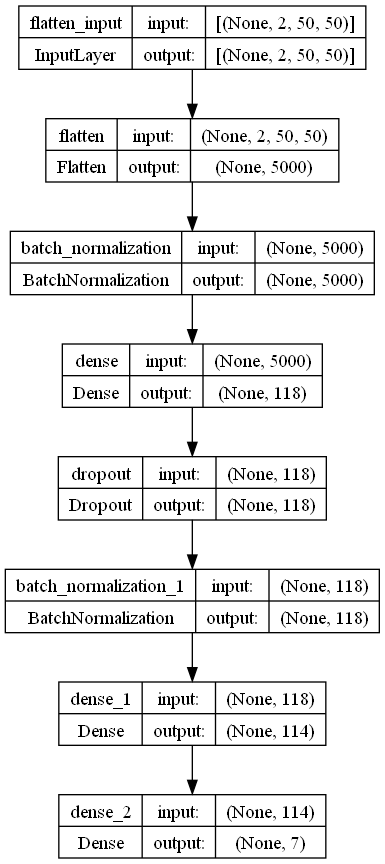

In [27]:
keras.utils.plot_model(model,show_shapes=True)

# Entrenamos el modelo

In [28]:
from keras.optimizers import Adam
optimizer = Adam(learning_rate=0.001,clipvalue=100.0)

In [29]:
def total_mae_loss(y_true, y_pred):
    total_loss = 0
    num_parameters = 7
    for i in range(num_parameters):
        total_loss += tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])
    tf.print(y_true, summarize = -1)
    tf.print(y_pred, summarize = -1)
    return total_loss / num_parameters

In [30]:
coeficientesnombres = ('a_1', 'a_2', 'b_1', 'b_2', 'd_1', 'd_2', 'n')

def mse_component(i):
    def mse_i(y_true, y_pred):
        return tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])

    mse_i.__name__ = coeficientesnombres[i]
    return mse_i

def mean_metric(y_true, y_pred):
    total_loss = 0
    for i in range(7):
        total_loss += mse_component(i)(y_true, y_pred)
    sum_of_true_coefficients = tf.reduce_sum(y_true, axis=-1)
    return total_loss / sum_of_true_coefficients

metrics = [mse_component(i) for i in range(7)] + [mean_metric]

In [31]:
model.compile(optimizer=optimizer,
              loss= 'mean_squared_error',
              metrics=metrics)

In [1]:
def scheduler(epoch, lr):
  if epoch < 400:
    return lr
  else:
    return -1.65e-6*epoch +  0.00166

def adaptive_learning_rate(epoch):
    initial_lr = 0.001
    final_lr = 0.00001  # Updated final learning rate
    start_decay_epoch = 80
    end_decay_epoch = 10000
    
    if epoch < start_decay_epoch:
        return initial_lr
    elif epoch >= start_decay_epoch and epoch <= end_decay_epoch:
        lr_range = initial_lr - final_lr
        decay_epochs = end_decay_epoch - start_decay_epoch
        decay_per_epoch = lr_range / decay_epochs
        return initial_lr - (epoch - start_decay_epoch) * decay_per_epoch
    else:
        return final_lr

In [33]:
val_epochs = 10000

early_stop = tf.keras.callbacks.EarlyStopping( monitor = 'val_loss', patience = 100,verbose = 1, 
                                              restore_best_weights = True)

reduce_lr = tf.keras.callbacks.LearningRateScheduler(adaptive_learning_rate)
history = model.fit(train_dataset, validation_data=val_dataset, epochs= val_epochs, callbacks=[reduce_lr, early_stop])

Epoch 1/10000
70/70 [==============================] - 2s 12ms/step - loss: 9.5561 - a_1: 1.9869 - a_2: 2.1407 - b_1: 1.4410 - b_2: 1.2988 - d_1: 1.0138 - d_2: 1.0645 - n: 1.3082 - mean_metric: 0.3203 - val_loss: 6.1568 - val_a_1: 1.6169 - val_a_2: 1.8446 - val_b_1: 1.7252 - val_b_2: 1.9263 - val_d_1: 1.5722 - val_d_2: 1.6382 - val_n: 1.2014 - val_mean_metric: 0.3576 - lr: 0.0010
Epoch 2/10000
70/70 [==============================] - 1s 8ms/step - loss: 3.1177 - a_1: 1.0454 - a_2: 1.0543 - b_1: 0.8978 - b_2: 0.8957 - d_1: 0.8477 - d_2: 0.8533 - n: 1.2001 - mean_metric: 0.2122 - val_loss: 3.1251 - val_a_1: 1.3012 - val_a_2: 1.2401 - val_b_1: 1.2715 - val_b_2: 1.1901 - val_d_1: 1.0059 - val_d_2: 1.0425 - val_n: 1.1963 - val_mean_metric: 0.2559 - lr: 0.0010
Epoch 3/10000
70/70 [==============================] - 1s 8ms/step - loss: 2.4771 - a_1: 0.9628 - a_2: 0.9430 - b_1: 0.8324 - b_2: 0.8595 - d_1: 0.8307 - d_2: 0.8194 - n: 1.2010 - mean_metric: 0.2014 - val_loss: 2.2379 - val_a_1: 0.940

70/70 [==============================] - 1s 8ms/step - loss: 0.8578 - a_1: 0.5591 - a_2: 0.5135 - b_1: 0.4684 - b_2: 0.4726 - d_1: 0.4392 - d_2: 0.4760 - n: 0.4841 - mean_metric: 0.1066 - val_loss: 0.5724 - val_a_1: 0.2180 - val_a_2: 0.3610 - val_b_1: 0.2236 - val_b_2: 0.2144 - val_d_1: 0.2492 - val_d_2: 0.2430 - val_n: 0.2579 - val_mean_metric: 0.0548 - lr: 0.0010
Epoch 44/10000
70/70 [==============================] - 1s 8ms/step - loss: 0.8654 - a_1: 0.5576 - a_2: 0.5171 - b_1: 0.4717 - b_2: 0.4921 - d_1: 0.4675 - d_2: 0.4685 - n: 0.4761 - mean_metric: 0.1078 - val_loss: 0.5907 - val_a_1: 0.2749 - val_a_2: 0.2898 - val_b_1: 0.3099 - val_b_2: 0.2670 - val_d_1: 0.2585 - val_d_2: 0.3350 - val_n: 0.2495 - val_mean_metric: 0.0616 - lr: 0.0010
Epoch 45/10000
70/70 [==============================] - 1s 8ms/step - loss: 0.8430 - a_1: 0.5303 - a_2: 0.5171 - b_1: 0.4573 - b_2: 0.4852 - d_1: 0.4688 - d_2: 0.4577 - n: 0.4738 - mean_metric: 0.1059 - val_loss: 0.5623 - val_a_1: 0.2033 - val_a_2: 

70/70 [==============================] - 1s 8ms/step - loss: 0.7230 - a_1: 0.4881 - a_2: 0.4924 - b_1: 0.4511 - b_2: 0.4580 - d_1: 0.4305 - d_2: 0.4258 - n: 0.4081 - mean_metric: 0.0985 - val_loss: 0.4811 - val_a_1: 0.3096 - val_a_2: 0.2740 - val_b_1: 0.2220 - val_b_2: 0.2136 - val_d_1: 0.1984 - val_d_2: 0.1896 - val_n: 0.2353 - val_mean_metric: 0.0510 - lr: 9.9960e-04
Epoch 86/10000
70/70 [==============================] - 1s 8ms/step - loss: 0.7236 - a_1: 0.4962 - a_2: 0.4957 - b_1: 0.4471 - b_2: 0.4452 - d_1: 0.4306 - d_2: 0.4347 - n: 0.4130 - mean_metric: 0.0988 - val_loss: 0.4725 - val_a_1: 0.1820 - val_a_2: 0.2932 - val_b_1: 0.2436 - val_b_2: 0.2009 - val_d_1: 0.2518 - val_d_2: 0.2163 - val_n: 0.2250 - val_mean_metric: 0.0501 - lr: 9.9950e-04
Epoch 87/10000
70/70 [==============================] - 1s 8ms/step - loss: 0.7228 - a_1: 0.4777 - a_2: 0.4888 - b_1: 0.4669 - b_2: 0.4532 - d_1: 0.4672 - d_2: 0.4269 - n: 0.4068 - mean_metric: 0.0995 - val_loss: 0.4548 - val_a_1: 0.1984 - v

70/70 [==============================] - 1s 8ms/step - loss: 0.6650 - a_1: 0.4865 - a_2: 0.4638 - b_1: 0.4248 - b_2: 0.4406 - d_1: 0.4257 - d_2: 0.4089 - n: 0.3856 - mean_metric: 0.0948 - val_loss: 0.4168 - val_a_1: 0.1907 - val_a_2: 0.2938 - val_b_1: 0.1851 - val_b_2: 0.2276 - val_d_1: 0.1824 - val_d_2: 0.2080 - val_n: 0.1719 - val_mean_metric: 0.0453 - lr: 9.9541e-04
Epoch 128/10000
70/70 [==============================] - 1s 8ms/step - loss: 0.6808 - a_1: 0.4924 - a_2: 0.4784 - b_1: 0.4309 - b_2: 0.4461 - d_1: 0.4432 - d_2: 0.4212 - n: 0.3822 - mean_metric: 0.0966 - val_loss: 0.4412 - val_a_1: 0.2887 - val_a_2: 0.2715 - val_b_1: 0.3079 - val_b_2: 0.2469 - val_d_1: 0.1826 - val_d_2: 0.2013 - val_n: 0.1607 - val_mean_metric: 0.0515 - lr: 9.9531e-04
Epoch 129/10000
70/70 [==============================] - 1s 8ms/step - loss: 0.6758 - a_1: 0.5003 - a_2: 0.4822 - b_1: 0.4051 - b_2: 0.4473 - d_1: 0.4339 - d_2: 0.4357 - n: 0.3807 - mean_metric: 0.0963 - val_loss: 0.4391 - val_a_1: 0.2416 -

70/70 [==============================] - 1s 8ms/step - loss: 0.6446 - a_1: 0.4653 - a_2: 0.4550 - b_1: 0.4183 - b_2: 0.4432 - d_1: 0.4347 - d_2: 0.4246 - n: 0.3790 - mean_metric: 0.0943 - val_loss: 0.4002 - val_a_1: 0.2407 - val_a_2: 0.2040 - val_b_1: 0.1885 - val_b_2: 0.2348 - val_d_1: 0.2123 - val_d_2: 0.2399 - val_n: 0.1559 - val_mean_metric: 0.0458 - lr: 9.9122e-04
Epoch 170/10000
70/70 [==============================] - 1s 8ms/step - loss: 0.6262 - a_1: 0.4691 - a_2: 0.4389 - b_1: 0.4290 - b_2: 0.4347 - d_1: 0.4159 - d_2: 0.4032 - n: 0.3704 - mean_metric: 0.0925 - val_loss: 0.3887 - val_a_1: 0.1927 - val_a_2: 0.2007 - val_b_1: 0.2289 - val_b_2: 0.2386 - val_d_1: 0.2120 - val_d_2: 0.1888 - val_n: 0.1627 - val_mean_metric: 0.0442 - lr: 9.9112e-04
Epoch 171/10000
70/70 [==============================] - 1s 8ms/step - loss: 0.6358 - a_1: 0.4656 - a_2: 0.4631 - b_1: 0.4279 - b_2: 0.4484 - d_1: 0.4267 - d_2: 0.4161 - n: 0.3617 - mean_metric: 0.0940 - val_loss: 0.3858 - val_a_1: 0.2109 -

70/70 [==============================] - 1s 8ms/step - loss: 0.6169 - a_1: 0.4603 - a_2: 0.4440 - b_1: 0.4512 - b_2: 0.4385 - d_1: 0.4094 - d_2: 0.4016 - n: 0.3591 - mean_metric: 0.0926 - val_loss: 0.3911 - val_a_1: 0.2103 - val_a_2: 0.2205 - val_b_1: 0.2625 - val_b_2: 0.2391 - val_d_1: 0.1848 - val_d_2: 0.2011 - val_n: 0.1662 - val_mean_metric: 0.0461 - lr: 9.8703e-04
Epoch 212/10000
70/70 [==============================] - 1s 8ms/step - loss: 0.6109 - a_1: 0.4730 - a_2: 0.4349 - b_1: 0.4127 - b_2: 0.4254 - d_1: 0.4205 - d_2: 0.4007 - n: 0.3563 - mean_metric: 0.0913 - val_loss: 0.3859 - val_a_1: 0.2775 - val_a_2: 0.2199 - val_b_1: 0.2099 - val_b_2: 0.2050 - val_d_1: 0.1902 - val_d_2: 0.2452 - val_n: 0.1523 - val_mean_metric: 0.0465 - lr: 9.8693e-04
Epoch 213/10000
70/70 [==============================] - 1s 8ms/step - loss: 0.6107 - a_1: 0.4642 - a_2: 0.4639 - b_1: 0.4239 - b_2: 0.4275 - d_1: 0.4153 - d_2: 0.4035 - n: 0.3599 - mean_metric: 0.0924 - val_loss: 0.3783 - val_a_1: 0.1968 -

... (45 outputs left out)

70/70 [==============================] - 1s 8ms/step - loss: 0.4010 - a_1: 0.3972 - a_2: 0.3712 - b_1: 0.3462 - b_2: 0.3869 - d_1: 0.3651 - d_2: 0.3740 - n: 0.2870 - mean_metric: 0.0790 - val_loss: 0.2344 - val_a_1: 0.2121 - val_a_2: 0.1604 - val_b_1: 0.1912 - val_b_2: 0.1915 - val_d_1: 0.1723 - val_d_2: 0.2042 - val_n: 0.1165 - val_mean_metric: 0.0387 - lr: 7.9422e-04
Epoch 2144/10000
70/70 [==============================] - 1s 8ms/step - loss: 0.3964 - a_1: 0.4018 - a_2: 0.3705 - b_1: 0.3439 - b_2: 0.3654 - d_1: 0.3569 - d_2: 0.3630 - n: 0.2857 - mean_metric: 0.0777 - val_loss: 0.2353 - val_a_1: 0.2202 - val_a_2: 0.1585 - val_b_1: 0.1912 - val_b_2: 0.2034 - val_d_1: 0.1619 - val_d_2: 0.2046 - val_n: 0.1287 - val_mean_metric: 0.0394 - lr: 7.9412e-04
Epoch 2145/10000
70/70 [==============================] - 1s 8ms/step - loss: 0.3879 - a_1: 0.3791 - a_2: 0.3685 - b_1: 0.3419 - b_2: 0.3707 - d_1: 0.3624 - d_2: 0.3628 - n: 0.2867 - mean_metric: 0.0772 - val_loss: 0.2272 - val_a_1: 0.1938

70/70 [==============================] - 1s 8ms/step - loss: 0.3964 - a_1: 0.4125 - a_2: 0.3754 - b_1: 0.3600 - b_2: 0.3815 - d_1: 0.3445 - d_2: 0.3666 - n: 0.2780 - mean_metric: 0.0787 - val_loss: 0.2338 - val_a_1: 0.1987 - val_a_2: 0.1710 - val_b_1: 0.1747 - val_b_2: 0.2356 - val_d_1: 0.1612 - val_d_2: 0.1889 - val_n: 0.1232 - val_mean_metric: 0.0389 - lr: 7.9002e-04
Epoch 2186/10000
70/70 [==============================] - 1s 8ms/step - loss: 0.3961 - a_1: 0.4099 - a_2: 0.3699 - b_1: 0.3452 - b_2: 0.3776 - d_1: 0.3728 - d_2: 0.3511 - n: 0.2900 - mean_metric: 0.0786 - val_loss: 0.2342 - val_a_1: 0.1938 - val_a_2: 0.1490 - val_b_1: 0.1809 - val_b_2: 0.1958 - val_d_1: 0.1950 - val_d_2: 0.2240 - val_n: 0.1231 - val_mean_metric: 0.0391 - lr: 7.8992e-04
Epoch 2187/10000
70/70 [==============================] - 1s 8ms/step - loss: 0.3923 - a_1: 0.4067 - a_2: 0.3725 - b_1: 0.3536 - b_2: 0.3668 - d_1: 0.3535 - d_2: 0.3569 - n: 0.2783 - mean_metric: 0.0777 - val_loss: 0.2349 - val_a_1: 0.2395

70/70 [==============================] - 1s 8ms/step - loss: 0.3926 - a_1: 0.3912 - a_2: 0.3683 - b_1: 0.3605 - b_2: 0.3721 - d_1: 0.3554 - d_2: 0.3730 - n: 0.2799 - mean_metric: 0.0781 - val_loss: 0.2352 - val_a_1: 0.2056 - val_a_2: 0.1680 - val_b_1: 0.1881 - val_b_2: 0.2173 - val_d_1: 0.1716 - val_d_2: 0.1898 - val_n: 0.1208 - val_mean_metric: 0.0391 - lr: 7.8583e-04
Epoch 2228/10000
70/70 [==============================] - 1s 8ms/step - loss: 0.4002 - a_1: 0.3894 - a_2: 0.3751 - b_1: 0.3459 - b_2: 0.3726 - d_1: 0.3743 - d_2: 0.3810 - n: 0.2856 - mean_metric: 0.0788 - val_loss: 0.2292 - val_a_1: 0.1989 - val_a_2: 0.1790 - val_b_1: 0.1758 - val_b_2: 0.2018 - val_d_1: 0.1910 - val_d_2: 0.1994 - val_n: 0.1192 - val_mean_metric: 0.0393 - lr: 7.8573e-04
Epoch 2229/10000
70/70 [==============================] - 1s 8ms/step - loss: 0.3818 - a_1: 0.3862 - a_2: 0.3586 - b_1: 0.3471 - b_2: 0.3633 - d_1: 0.3537 - d_2: 0.3625 - n: 0.2904 - mean_metric: 0.0769 - val_loss: 0.2230 - val_a_1: 0.2041

70/70 [==============================] - 1s 8ms/step - loss: 0.3885 - a_1: 0.4097 - a_2: 0.3613 - b_1: 0.3516 - b_2: 0.3546 - d_1: 0.3578 - d_2: 0.3558 - n: 0.2817 - mean_metric: 0.0773 - val_loss: 0.2290 - val_a_1: 0.1997 - val_a_2: 0.1620 - val_b_1: 0.1769 - val_b_2: 0.1928 - val_d_1: 0.1750 - val_d_2: 0.1836 - val_n: 0.1158 - val_mean_metric: 0.0374 - lr: 7.8164e-04
Epoch 2270/10000
70/70 [==============================] - 1s 8ms/step - loss: 0.3960 - a_1: 0.3953 - a_2: 0.3631 - b_1: 0.3585 - b_2: 0.3710 - d_1: 0.3685 - d_2: 0.3627 - n: 0.2789 - mean_metric: 0.0780 - val_loss: 0.2360 - val_a_1: 0.2148 - val_a_2: 0.1694 - val_b_1: 0.1760 - val_b_2: 0.1958 - val_d_1: 0.1755 - val_d_2: 0.2131 - val_n: 0.1157 - val_mean_metric: 0.0391 - lr: 7.8154e-04
Epoch 2271/10000
70/70 [==============================] - 1s 8ms/step - loss: 0.3942 - a_1: 0.3978 - a_2: 0.3629 - b_1: 0.3659 - b_2: 0.3718 - d_1: 0.3591 - d_2: 0.3522 - n: 0.2842 - mean_metric: 0.0779 - val_loss: 0.2296 - val_a_1: 0.1792

# Analizamos accuracy y loss

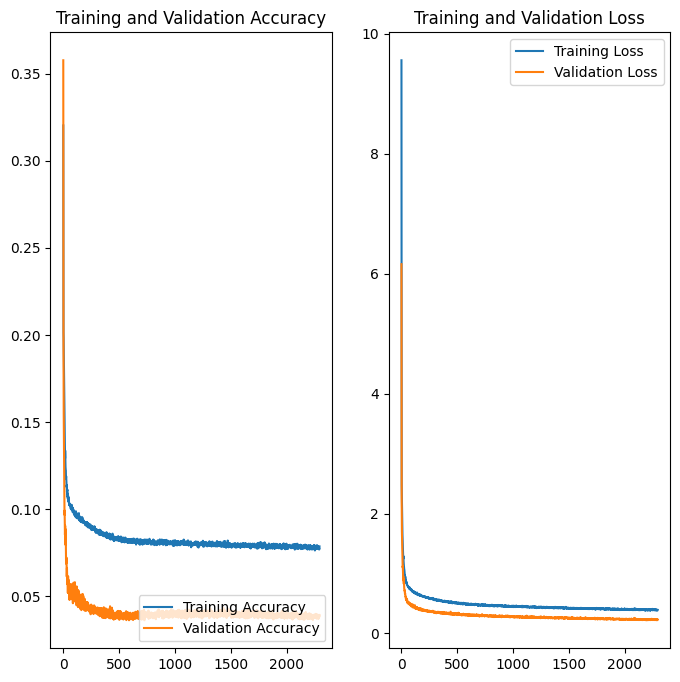

In [35]:
acc = history.history['mean_metric']
val_acc = history.history['val_mean_metric']

loss = history.history['loss']
val_loss = history.history['val_loss']

#epochs_range = range(val_epochs)
epochs_range = range(2296)
plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

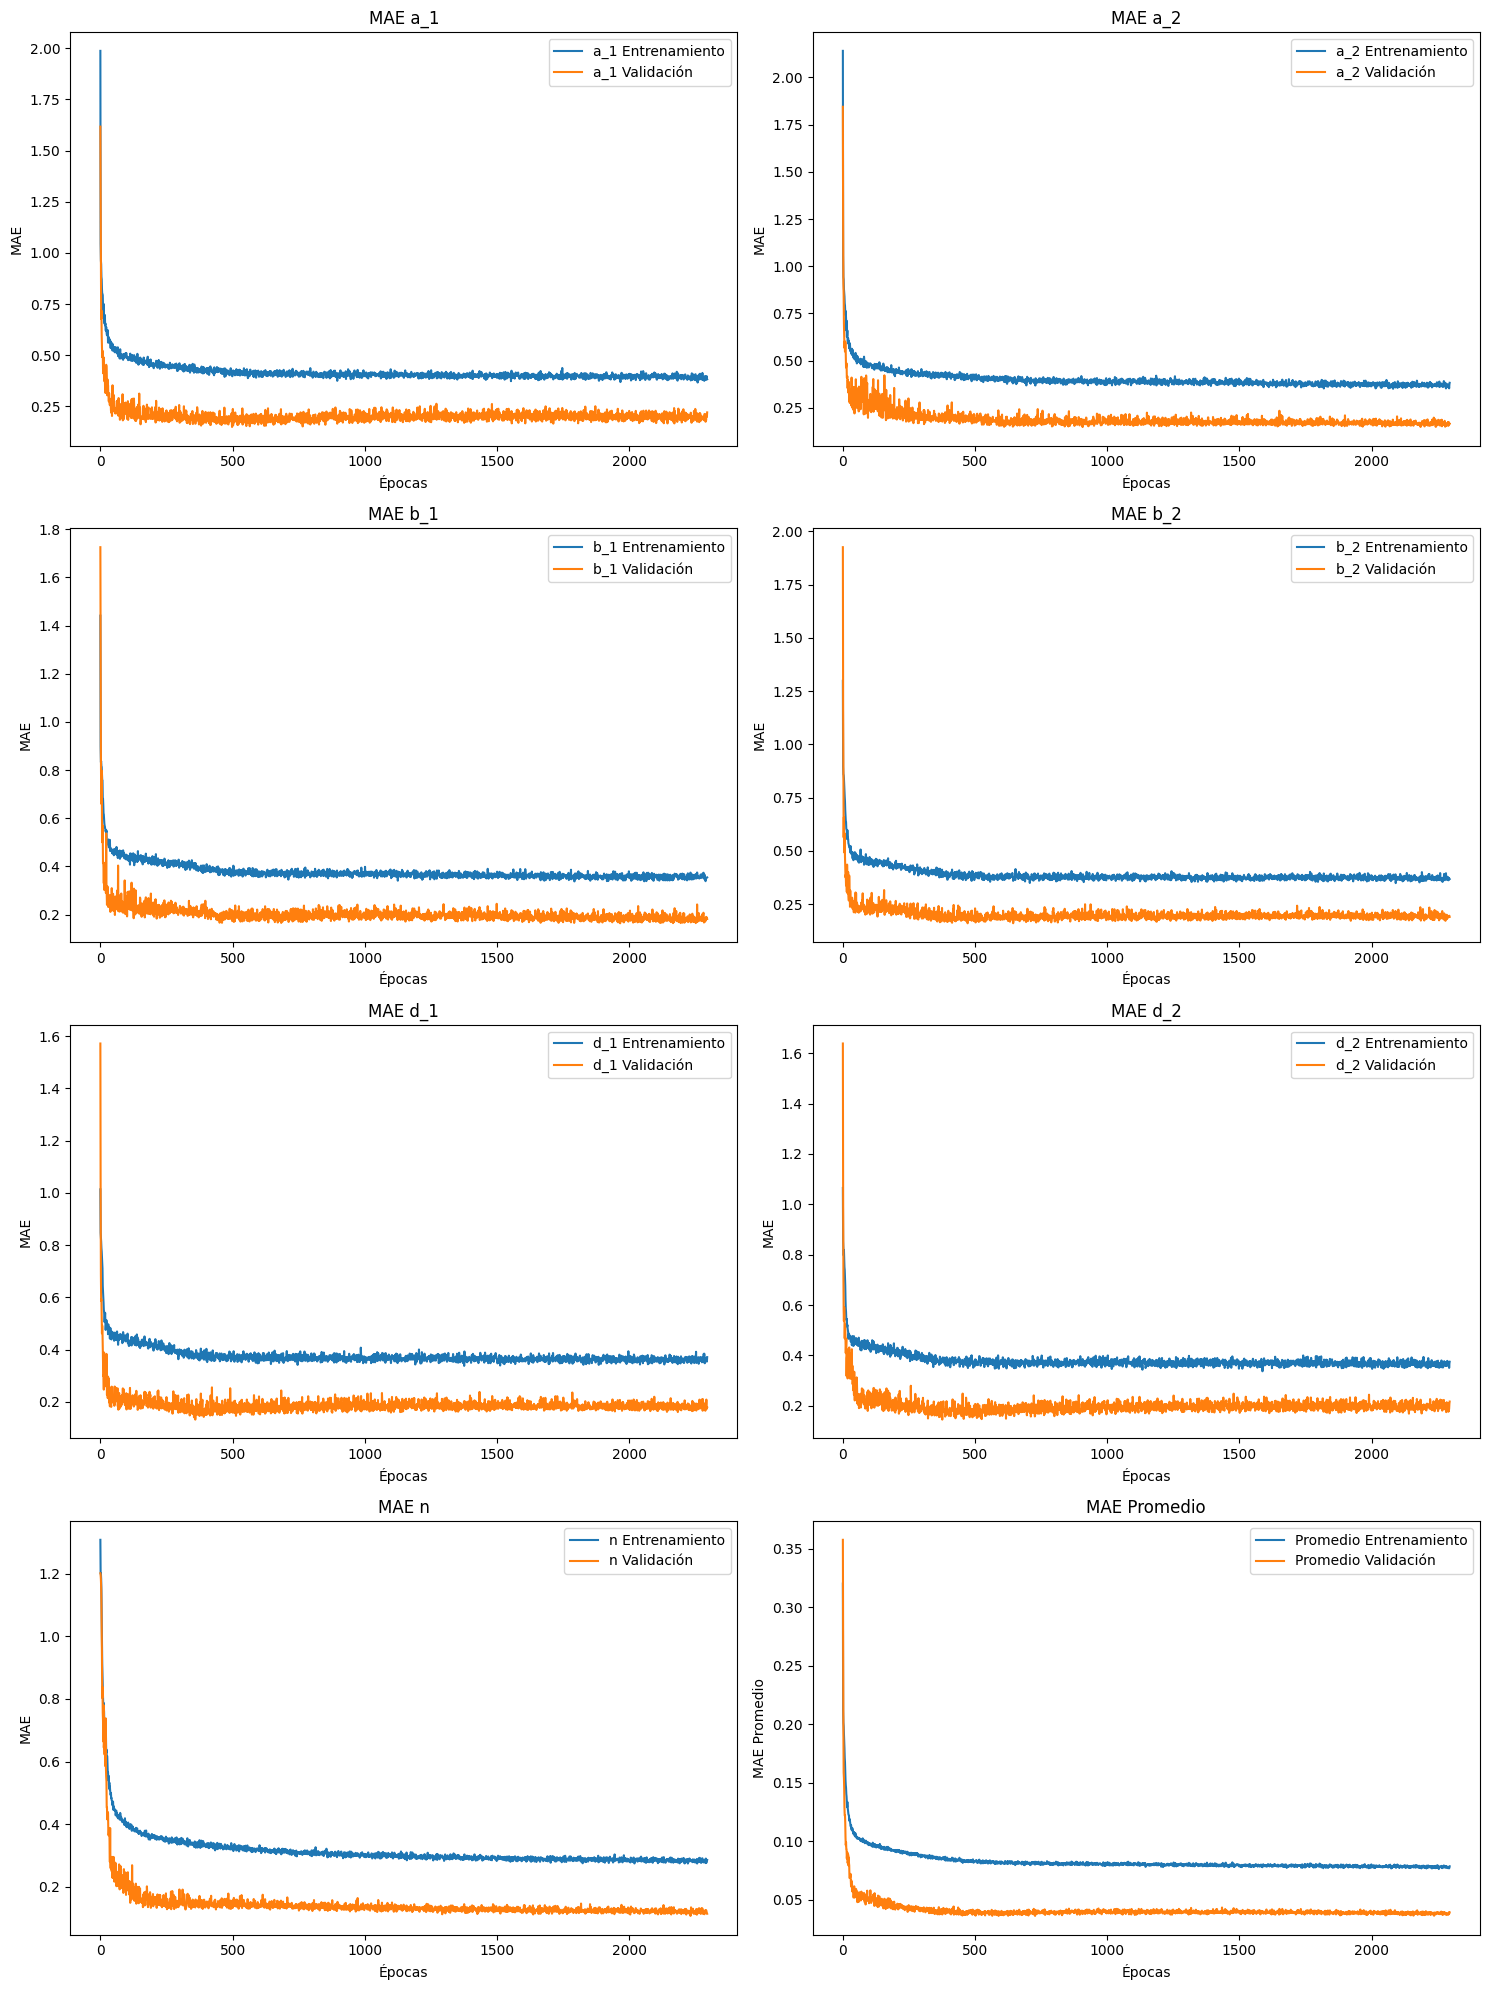

In [36]:
# Número de coeficientes más uno para la métrica adicional
n_coef = len(coeficientesnombres) + 1

# Número de filas y columnas para los subplots
n_rows = (n_coef + 1) // 2
n_cols = 2

# Crear una figura más grande para acomodar todos los subplots
plt.figure(figsize=(15, 5 * n_rows))

# Crear un subplot para cada coeficiente
for i, name in enumerate(coeficientesnombres):
    plt.subplot(n_rows, n_cols, i + 1)
    plt.plot(history.history[name ], label=name + ' Entrenamiento')
    plt.plot(history.history['val_' + name ], label=name + ' Validación')
    plt.title('MAE ' + name)
    plt.xlabel('Épocas')
    plt.ylabel('MAE')
    plt.legend()

# Agregar un subplot para la métrica prom_per
plt.subplot(n_rows, n_cols, n_coef)
plt.plot(history.history['mean_metric'], label='Promedio Entrenamiento')
plt.plot(history.history['val_mean_metric'], label='Promedio Validación')
plt.title('MAE Promedio')
plt.xlabel('Épocas')
plt.ylabel('MAE Promedio')
plt.legend()

# Ajustar el diseño para asegurarse de que todo encaje bien
plt.tight_layout()
plt.show()

# Evaluamos el modelo

In [37]:
test_loss, test_a1, test_a2, test_b1, test_b2, test_d1, test_d2, test_n, testprom_per = model.evaluate(
    campvectest, coefcampvectest)

32/32 [==============================] - 0s 1ms/step - loss: 0.2207 - a_1: 0.1963 - a_2: 0.1628 - b_1: 0.1654 - b_2: 0.1832 - d_1: 0.1828 - d_2: 0.2023 - n: 0.1265 - mean_metric: 0.0380


In [38]:
predictions = model.predict(campvectest)

32/32 [==============================] - 0s 772us/step


In [39]:
from sklearn.metrics import mean_absolute_error
import numpy as np

# Calcula el MAE
mae = mean_absolute_error(coefcampvectest, predictions)

# Calcula la desviación estándar del error
error = coefcampvectest - predictions
std_dev = np.std(error)

# Calcula el error absoluto máximo
max_error = np.max(np.abs(error))

print(f"MAE: {mae}, Desviación estándar del error: {std_dev}, Error absoluto máximo: {max_error}")

MAE: 0.17452676551682605, Desviación estándar del error: 0.21268317515009638, Error absoluto máximo: 0.8793785572052002


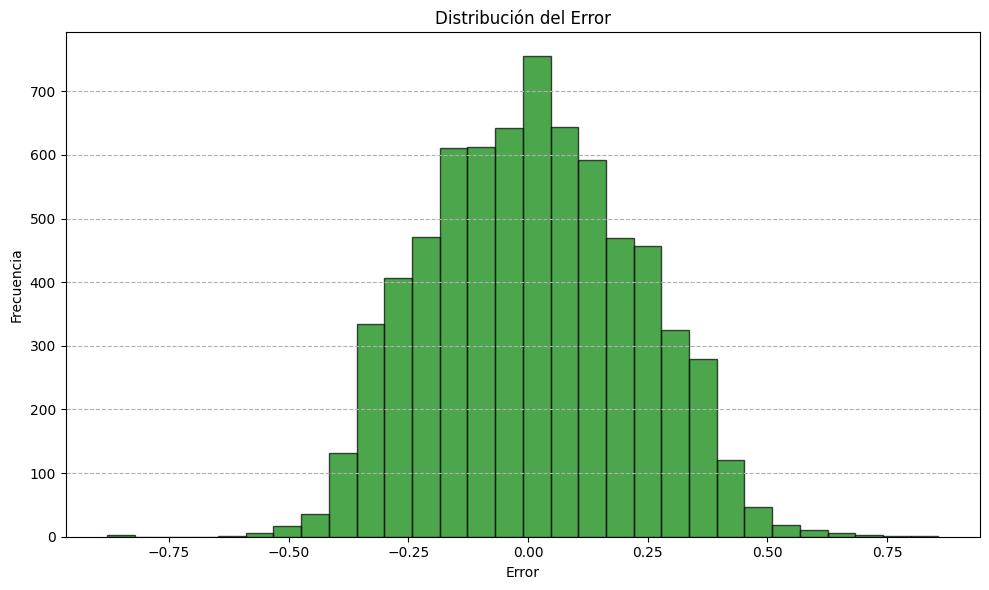

In [40]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))  # Establece el tamaño del gráfico
plt.hist(error.flatten(), bins=30, edgecolor='black', alpha=0.7, color = 'green')  # Añade bordes negros a las barras y ajusta la transparencia
plt.title('Distribución del Error')  # Añade un título al gráfico
plt.xlabel('Error')  # Etiqueta el eje x
plt.ylabel('Frecuencia')  # Etiqueta el eje y
plt.grid(axis='y', linestyle='--')  # Añade una cuadrícula horizontal
plt.tight_layout()  # Ajusta el diseño para evitar que se recorten las etiquetas
plt.show()

In [41]:
# Calcula el error absoluto para cada dato
absolute_error = np.abs(coefcampvectest - predictions)

# Calcula el error para cada dato
error = coefcampvectest - predictions

# Calcula la suma de los valores reales para cada dato
sum_real_values = np.sum(coefcampvectest, axis=-1)

# Divide el error absoluto por la suma de los valores reales para cada dato
relative_error_per_data = np.sum(absolute_error, axis=-1) / sum_real_values

# Calcula el MAE relativo como la media de los errores relativos
relative_mae = np.mean(relative_error_per_data)

# Divide el error por la suma de los valores reales para cada dato
relative_error_per_data_std_max = np.sum(error, axis=-1) / sum_real_values

# Calcula la desviación estándar del error relativo
relative_std_dev = np.std(relative_error_per_data_std_max)

# Calcula el error absoluto máximo relativo
relative_max_error = np.max(np.abs(relative_error_per_data_std_max))

print(f"MAE relativo: {relative_mae}")
print(f"Desviación estándar del error relativo: {relative_std_dev}")
print(f"Error absoluto máximo relativo: {relative_max_error}")


MAE relativo: 0.03817547163918471
Desviación estándar del error relativo: 0.016424042070537444
Error absoluto máximo relativo: 0.09707969799637794


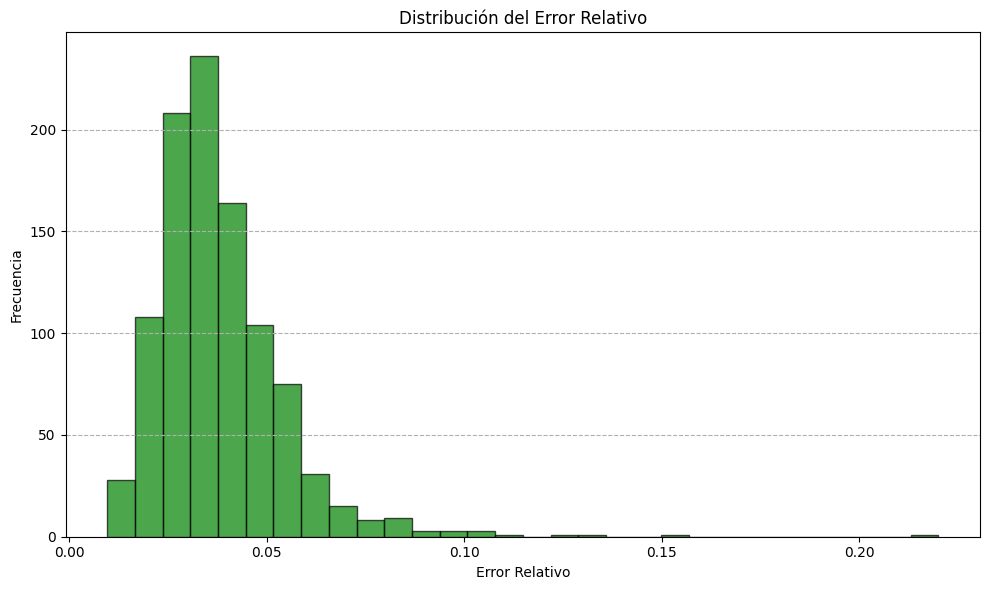

In [42]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))  # Establece el tamaño del gráfico
plt.hist(relative_error_per_data, bins=30, edgecolor='black', alpha=0.7, color = 'green')  # Añade bordes negros a las barras y ajusta la transparencia
plt.title('Distribución del Error Relativo')  # Añade un título al gráfico
plt.xlabel('Error Relativo')  # Etiqueta el eje x
plt.ylabel('Frecuencia')      # Etiqueta el eje y
plt.grid(axis='y', linestyle='--')  # Añade una cuadrícula horizontal
plt.tight_layout()  # Ajusta el diseño para evitar que se recorten las etiquetas
plt.show()

# Guardamos los datos accuracy y loss

In [43]:
df = pd.DataFrame.from_dict(history.history)
df.to_csv('../../../Gráficas finales/grid50_traj100/historycampvec50.csv', index=False)

# Guardamos el modelo

In [44]:
path_to_save = '../../../trained_models_clean/grid50_traj100'

In [45]:
model.save(path_to_save + '/campovectorial50.h5')

# Importamos el modelo

In [46]:
def custom_activation(x):
    return 10 * tf.nn.sigmoid(x)

In [47]:
coeficientesnombres = ('a_1', 'a_2', 'b_1', 'b_2', 'd_1', 'd_2', 'n')

def mse_component(i):
    def mse_i(y_true, y_pred):
        return tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])

    mse_i.__name__ = coeficientesnombres[i]
    return mse_i

def mean_metric(y_true, y_pred):
    total_loss = 0
    for i in range(7):
        total_loss += mse_component(i)(y_true, y_pred)
    sum_of_true_coefficients = tf.reduce_sum(y_true, axis=-1)
    return total_loss / sum_of_true_coefficients

metrics = [mse_component(i) for i in range(7)] + [mean_metric]

In [48]:
import keras
import tensorflow as tf
# Creación de un diccionario con todas las métricas personalizadas
custom_objects = {'custom_activation':custom_activation,'mean_metric': mean_metric}
for i in range(7):
    custom_objects[coeficientesnombres[i]] = mse_component(i)
new_model = keras.models.load_model('../../../trained_models_clean/grid50_traj100/campovectorial50.h5', custom_objects= custom_objects)

# Probamos el modelo con datos nuevos

## Creamos nuevos datos

In [49]:
import random
from scipy.integrate import solve_ivp

campvec = []
coef = []
contador = 0
for i in range(0, 1):
    # constantes
    a1 = random.randint(0, 10)
    a2 = random.randint(0, 10)
    b1 = random.randint(0, 10)
    b2 = random.randint(0, 10)
    d1 = random.randint(0, 10)
    d2 = random.randint(0, 10)
    n = random.randint(0, 5)

    coef1 = [a1, a2, b1, b2, d1, d2, n]
    coef.append(coef1)

    def f(t, y):

        # asignar a cada ODE a un elemento de vector
        X = y[0]
        Y = y[1]

        # definimos cada ODE
        # dX_dt=a1/(1+Y**n)-d1*X+b1
        # dY_dt=a2/(1+X**n)-d2*Y+b2
        dX_dt = a1/(1+Y**n)-d1*X+b1
        dY_dt = a2/(1+X**n)-d2*Y+b1

        return [dX_dt, dY_dt]

    x_range_neg = 0
    x_range_pos = 10
    y_range_neg = 0
    y_range_pos =10

    y1 = np.linspace(x_range_neg, x_range_pos, 50)
    y2 = np.linspace(y_range_neg, y_range_pos, 50)

    Y1, Y2 = np.meshgrid(y1, y2)
    
    t1 = 0

    u, v = np.zeros(Y1.shape), np.zeros(Y2.shape)

    NI, NJ = Y1.shape

    u1, v1 = f(t1, [Y1, Y2])
    u, v = f(t1, [Y1, Y2])
    M = (np.hypot(u, v))
    u /= M
    v /= M

    campvecci = np.append([u1], [v1], axis=0)

    campvec = campvecci
    print('--------------------------------------------')
    print(coef1)

    
campvec = np.array(campvec)
coef = np.array(coef)


--------------------------------------------
[3, 7, 3, 3, 9, 6, 4]


In [50]:
campvecnone = campvec[None, :]

## Predecimos con los datos nuevos

In [51]:
new_predictions = new_model.predict(campvecnone)
new_predictions = np.round(new_predictions)
new_predictions = np.clip(new_predictions, 0, None)
print(new_predictions)

1/1 [==============================] - 0s 44ms/step
[[3. 7. 3. 3. 9. 6. 4.]]


## Encontramos puntos de equilibrio datos reales

In [52]:
from scipy.optimize import fsolve
# Sistema de ecuaciones
def system(Y):
    X, Y = Y
    dX_dt = a1/(1+Y**n)-d1*X+b1
    dY_dt = a2/(1+X**n)-d2*Y+b1
    return [dX_dt, dY_dt]

# Adivinanza inicial para X, Y
initial_guess = [0, 0]

# Encontrar los puntos de equilibrio
primer_cuadrante_reales = fsolve(system, initial_guess)
primer_cuadrante_reales = tuple(primer_cuadrante_reales)


print(primer_cuadrante_reales)

(0.37343558293444956, 1.6444107886014394)


## Graficamos con los coeficientes reales

Text(0, 0.5, 'Concentración Y')

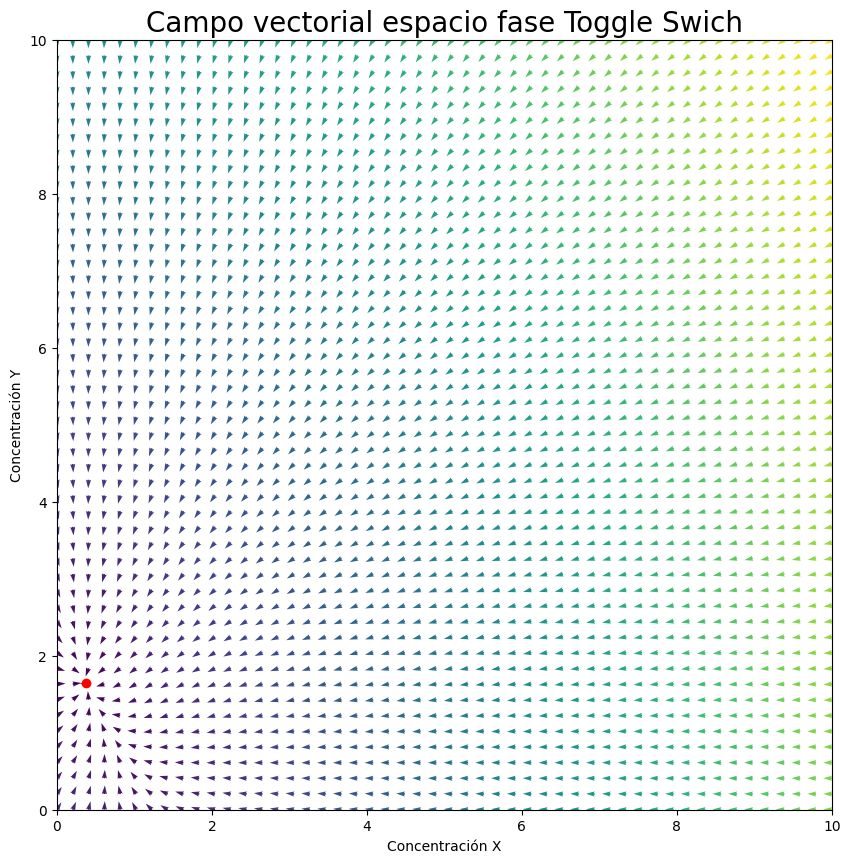

In [53]:
import matplotlib.pyplot as plt

x_values = primer_cuadrante_reales[0]
y_values =primer_cuadrante_reales[1]
y1 = np.linspace(0, 10, 50)
y2 = np.linspace(0, 10, 50)
Y1, Y2 = np.meshgrid(y1, y2)
t1 = 0
u, v = np.zeros(Y1.shape), np.zeros(Y2.shape)
NI, NJ = Y1.shape        
u,v = np.array(campvec)[0,:,:], np.array(campvec)[1,:,:]
M = (np.hypot(u,v))
u /= M
v /= M

plt.figure(figsize=(10,10))
Q = plt.quiver(Y1, Y2, u, v, M, angles='xy')
plt.title('Campo vectorial espacio fase Toggle Swich', fontsize=20)
plt.xlim([0, 10])
plt.ylim([0, 10])
plt.scatter(x_values, y_values, color='red')  # Puedes cambiar el color como prefieras
plt.xlabel('Concentración X')
plt.ylabel('Concentración Y')

## Encontramos puntos de equilibro datos predecidos

In [54]:
a1pred = new_predictions[0,0]
a2pred = new_predictions[0,1]
b1pred = new_predictions[0,2]
b2pred = new_predictions[0,3]
d1pred = new_predictions[0,4]
d2pred = new_predictions[0,5]
npred = new_predictions[0,6]

def systempred(Ypred):
    Xpred, Ypred = Ypred
    dXpred_dt = a1pred/(1+Ypred**npred)-d1pred*Xpred+b1pred
    dYpred_dt = a2pred/(1+Xpred**npred)-d2pred*Ypred+b1pred
    return [dXpred_dt, dYpred_dt]

# Adivinanza inicial para X, Y
initial_guesspred = [0, 0]

# Encontrar los puntos de equilibrio
primer_cuadrante_predecidos = fsolve(systempred, initial_guesspred)
primer_cuadrante_predecidos = tuple(primer_cuadrante_predecidos)


print(primer_cuadrante_predecidos)

(0.37343558293444956, 1.6444107886014394)


## Graficamos con los coeficientes predecidos

Text(0, 0.5, 'Concentración Y')

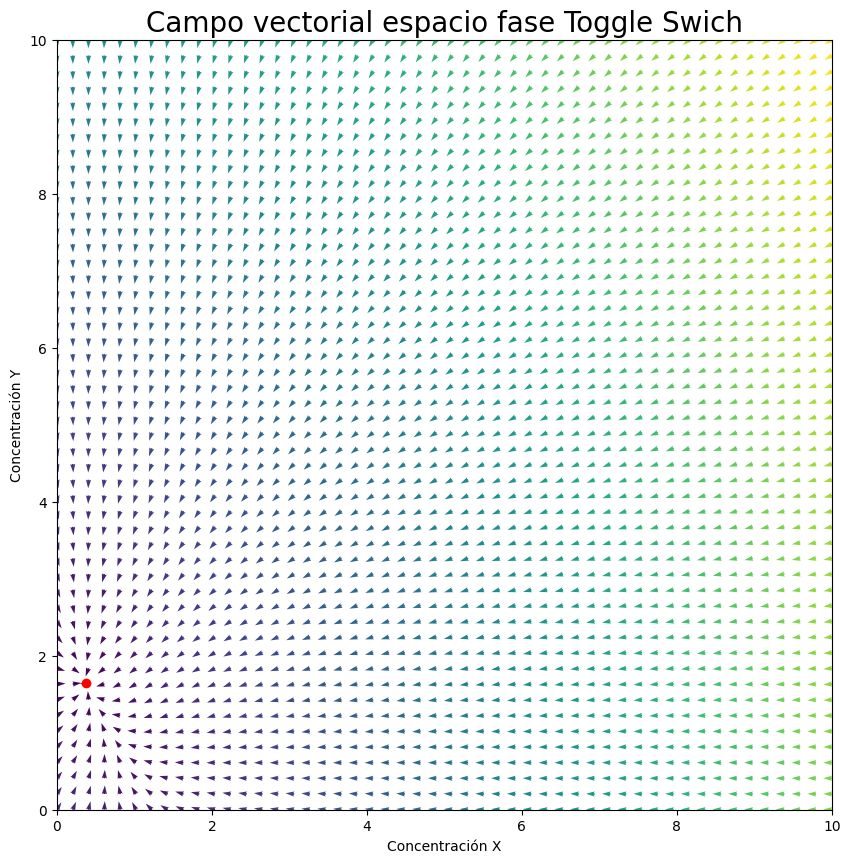

In [55]:
import matplotlib.pyplot as plt

def f(t, y):

    # asignar a cada ODE a un elemento de vector
    X = y[0]
    Y = y[1]

    # definimos cada ODE
    dX_dt = a1pred/(1+Y**npred)-d1pred*X+b1pred
    dY_dt = a2pred/(1+X**npred)-d2pred*Y+b1pred

    return [dX_dt, dY_dt]

x_range_neg = 0
x_range_pos = 10
y_range_neg = 0
y_range_pos = 10

y1pred = np.linspace(x_range_neg, x_range_pos, 50)
y2pred = np.linspace(y_range_neg, y_range_pos, 50)

Y1pred, Y2pred = np.meshgrid(y1pred, y2pred)
    
t1 = 0

upred, vpred = np.zeros(Y1pred.shape), np.zeros(Y2pred.shape)

NI, NJ = Y1.shape

u1pred, v1pred = f(t1, [Y1, Y2])
upred, vpred = f(t1, [Y1, Y2])
Mpred = (np.hypot(upred, vpred))
upred /= Mpred
vpred /= Mpred


x_valuespred = primer_cuadrante_predecidos[0]
y_valuespred =primer_cuadrante_predecidos[1]
plt.figure(figsize=(10, 10))
Q = plt.quiver(Y1, Y2, upred, vpred, Mpred, angles='xy')
plt.title('Campo vectorial espacio fase Toggle Swich', fontsize=20)
plt.xlim([x_range_neg, x_range_pos])
plt.ylim([y_range_neg, y_range_pos])
plt.scatter(x_valuespred, y_valuespred, color='red')  # Puedes cambiar el color como prefieras
plt.xlabel('Concentración X')
plt.ylabel('Concentración Y')

## Graficamos ambos

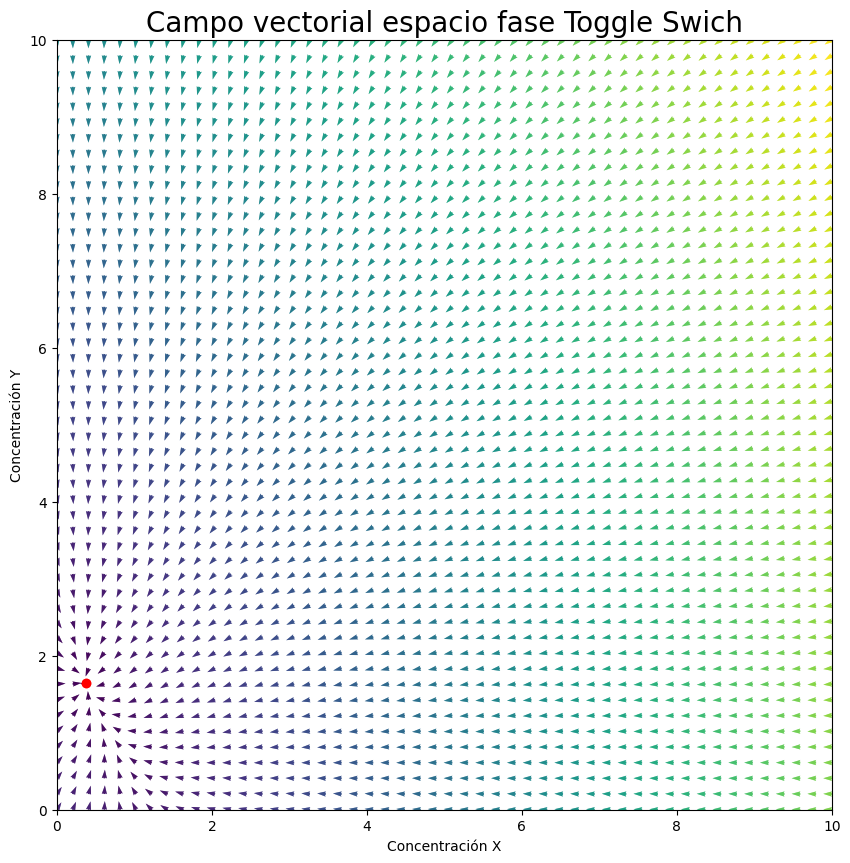

In [56]:
fig, ax = plt.subplots(figsize=(10, 10))

# Primero graficamos la predicción, que debería ser más clara (alpha < 1)
Q = ax.quiver(Y1, Y2, upred, vpred, Mpred, angles='xy', alpha=0.5)

# Luego, graficamos los datos originales, que serán más oscuros (alpha = 1)
Q1 = ax.quiver(Y1, Y2, u, v, M, angles='xy', alpha=1)

ax.scatter(x_valuespred, y_valuespred, color='red', alpha = 0.5)
ax.scatter(x_values, y_values, color='red', alpha = 1)
ax.set_title('Campo vectorial espacio fase Toggle Swich', fontsize=20)
ax.set_xlim([0, 10])
ax.set_ylim([0, 10])
ax.set_xlabel('Concentración X')
ax.set_ylabel('Concentración Y')

plt.show()

## Graficamos las diferencias

0.0


C:\Users\rafae\anaconda3\envs\tfcpu\lib\site-packages\matplotlib\quiver.py:646: RuntimeWarning: divide by zero encountered in double_scalars
  length = a * (widthu_per_lenu / (self.scale * self.width))
C:\Users\rafae\anaconda3\envs\tfcpu\lib\site-packages\matplotlib\quiver.py:646: RuntimeWarning: invalid value encountered in multiply
  length = a * (widthu_per_lenu / (self.scale * self.width))


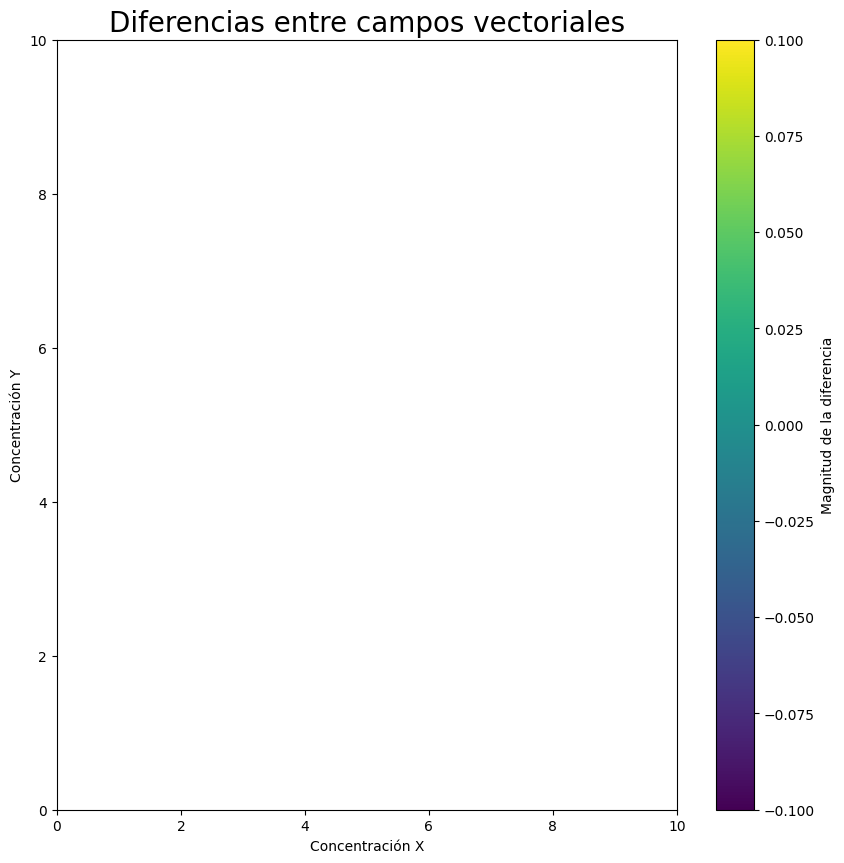

In [57]:
fig, ax = plt.subplots(figsize=(10, 10))

# Calculamos las diferencias
u_diff = u - upred
v_diff = v - vpred

# Ahora calculamos la magnitud
#M_diff = np.hypot(u_diff2, v_diff2)
M_diff = np.hypot(u_diff, v_diff)

#Calcula la magnitud de los vectores
magnitudes = np.sqrt(u_diff**2 + v_diff**2)

# Calcula el rango de las magnitudes
rango = (np.max(magnitudes) - np.min(magnitudes))*30
print(rango)
# Escala para las flechas. Aumenta este valor si las flechas son demasiado grandes.

# Graficamos las diferencias
#Q = ax.quiver(Y1, Y2, u_diff2, v_diff2, M_diff, angles='xy')
Q = ax.quiver(Y1, Y2, u_diff, v_diff, M_diff, angles='xy', scale = rango)
#Q = ax.quiver(Y1, Y2, u_diff, v_diff, M_diff, angles='xy')


ax.set_title('Diferencias entre campos vectoriales', fontsize=20)
ax.set_xlim([0, 10])
ax.set_ylim([0, 10])
ax.set_xlabel('Concentración X')
ax.set_ylabel('Concentración Y')

# Creamos una leyenda para la magnitud de las flechas
cbar = plt.colorbar(Q, ax=ax)
cbar.set_label('Magnitud de la diferencia')

plt.show()

## Errores relativos

C:\Users\rafae\anaconda3\envs\tfcpu\lib\site-packages\matplotlib\quiver.py:646: RuntimeWarning: divide by zero encountered in double_scalars
  length = a * (widthu_per_lenu / (self.scale * self.width))
C:\Users\rafae\anaconda3\envs\tfcpu\lib\site-packages\matplotlib\quiver.py:646: RuntimeWarning: invalid value encountered in multiply
  length = a * (widthu_per_lenu / (self.scale * self.width))


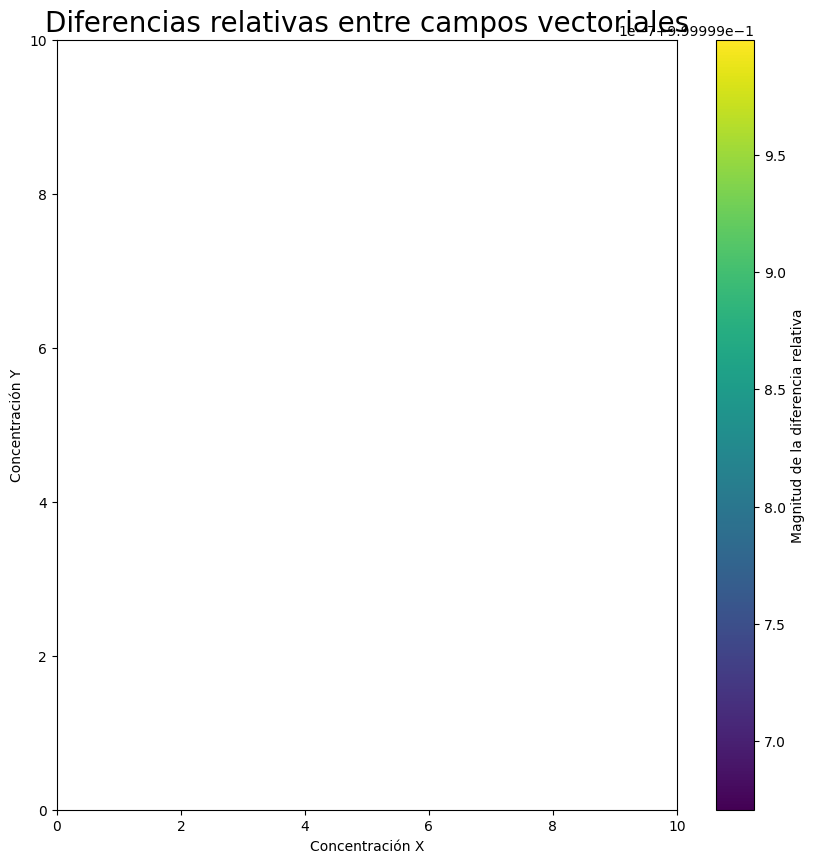

In [58]:
fig, ax = plt.subplots(figsize=(10, 10))

# Calculamos las diferencias
u_diff = u - upred
v_diff = v - vpred

# Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
epsilon = 1e-7

# Calculamos la magnitud del vector original y de la diferencia
M_orig = np.hypot(u1, v1) + epsilon
M_diff = np.hypot(u1pred, v1pred)

# Calculamos la diferencia relativa
M_diff_rel = M_diff / M_orig

#Calcula la magnitud de los vectores
magnitudes = np.sqrt(u_diff**2 + v_diff**2)

# Calcula el rango de las magnitudes
rango = (np.max(magnitudes) - np.min(magnitudes))*30

# Graficamos las diferencias relativas
Q = ax.quiver(Y1, Y2, u_diff, v_diff, M_diff_rel, angles='xy', scale = rango)

ax.set_title('Diferencias relativas entre campos vectoriales', fontsize=20)
ax.set_xlim([0, 10])
ax.set_ylim([0, 10])
ax.set_xlabel('Concentración X')
ax.set_ylabel('Concentración Y')

# Creamos una leyenda para la magnitud de las flechas
cbar = plt.colorbar(Q, ax=ax)
cbar.set_label('Magnitud de la diferencia relativa')

plt.show()

In [59]:
max_index_flattened = M_diff_rel.argmax()
max_coords = np.unravel_index(max_index_flattened, M_diff_rel.shape)
M_orig[max_coords]
print('El valor máximo de error relativo es de:', M_diff_rel.max() )
print('El valor de u1 en el error relativo máximo es:',u1[max_coords])
print('El valor de u1pred en el error relativo máximo es:',u1pred[max_coords])
print('El valor de v1 en el error relativo máximo es:',v1[max_coords])
print('El valor de v1pred en el error relativo máximo es:',v1pred[max_coords])

El valor máximo de error relativo es de: 0.9999999990385446
El valor de u1 en el error relativo máximo es: -86.999700029997
El valor de u1pred en el error relativo máximo es: -86.999700029997
El valor de v1 en el error relativo máximo es: -56.999300069993
El valor de v1pred en el error relativo máximo es: -56.999300069993


In [60]:
# Calculamos las diferencias
u_diff = u - upred
v_diff = v - vpred

# Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
epsilon = 1e-7

# Calculamos la magnitud del vector original y de la diferencia
M_orig = np.hypot(u, v) + epsilon
M_diff = np.hypot(u_diff, v_diff)

# Calculamos la diferencia relativa
M_diff_rel = M_diff / M_orig

# Aplicamos el filtro para la diferencia relativa mayor a 0.05
mask = M_diff_rel > 0.05

# Calculamos el porcentaje de puntos que cumplen con la condición
porcentaje = np.mean(mask) * 100

print(f"El porcentaje de puntos cuyo error relativo es mayor a 0.05 es {porcentaje:.2f}%")

El porcentaje de puntos cuyo error relativo es mayor a 0.05 es 0.00%


## Simulamos 10,000 veces

In [61]:
import numpy as np
import random
from scipy.optimize import fsolve

# Listas para almacenar los resultados
porcentajes = []

# Repetimos el proceso 10 veces
for repetir in range(10000):
    campvec = []
    coef = []
    # constantes
    a1 = random.randint(0, 10)
    a2 = random.randint(0, 10)
    b1 = random.randint(0, 10)
    b2 = random.randint(0, 10)
    d1 = random.randint(0, 10)
    d2 = random.randint(0, 10)
    n = random.randint(0, 5)

    coef1 = [a1, a2, b1, b2, d1, d2, n]
    coef.append(coef1)

    def f(t, y):

        # asignar a cada ODE a un elemento de vector
        X = y[0]
        Y = y[1]

        # definimos cada ODE
        dX_dt = a1/(1+Y**n)-d1*X+b1
        dY_dt = a2/(1+X**n)-d2*Y+b2

        return [dX_dt, dY_dt]

    x_range_neg = 0
    x_range_pos = 10
    y_range_neg = 0
    y_range_pos = 10

    y1 = np.linspace(x_range_neg, x_range_pos, 50)
    y2 = np.linspace(y_range_neg, y_range_pos, 50)

    Y1, Y2 = np.meshgrid(y1, y2)
    
    t1 = 0

    u, v = np.zeros(Y1.shape), np.zeros(Y2.shape)

    NI, NJ = Y1.shape

    u1, v1 = f(t1, [Y1, Y2])
    u, v = f(t1, [Y1, Y2])
    M = (np.hypot(u, v))
    u /= M
    v /= M

    campvecci = np.append([u1], [v1], axis=0)

    campvec = campvecci
    print('--------------------------------------------')
#    print(coef1)
    
    campvec = np.array(campvec)

    
    campvecnone = campvec[None, :]
    
    new_predictions = new_model.predict(campvecnone)
    new_predictions = np.round(new_predictions)
    new_predictions = np.clip(new_predictions, 0, None)
#    print(new_predictions)
    
    
    a1pred = new_predictions[0,0]
    a2pred = new_predictions[0,1]
    b1pred = new_predictions[0,2]
    b2pred = new_predictions[0,3]
    d1pred = new_predictions[0,4]
    d2pred = new_predictions[0,5]
    npred = new_predictions[0,6]
    
    def f(t, y):

        # asignar a cada ODE a un elemento de vector
        X = y[0]
        Y = y[1]

        # definimos cada ODE
        dX_dt = a1pred/(1+Y**npred)-d1pred*X+b1pred
        dY_dt = a2pred/(1+X**npred)-d2pred*Y+b2pred

        return [dX_dt, dY_dt]

    x_range_neg = 0
    x_range_pos = 10
    y_range_neg = 0
    y_range_pos = 10

    y1pred = np.linspace(x_range_neg, x_range_pos, 50)
    y2pred = np.linspace(y_range_neg, y_range_pos, 50)

    Y1pred, Y2pred = np.meshgrid(y1pred, y2pred)
    
    t1 = 0

    upred, vpred = np.zeros(Y1pred.shape), np.zeros(Y2pred.shape)

    NI, NJ = Y1.shape

    u1pred, v1pred = f(t1, [Y1, Y2])
    upred, vpred = f(t1, [Y1, Y2])
    Mpred = (np.hypot(upred, vpred))
    upred /= Mpred
    vpred /= Mpred

 # Calculamos las diferencias
    u_diff = u - upred
    v_diff = v - vpred

    # Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
    epsilon = 1e-7

    # Calculamos la magnitud del vector original y de la diferencia
    M_orig = np.hypot(u, v) + epsilon
    M_diff = np.hypot(u_diff, v_diff)

    # Calculamos la diferencia relativa
    M_diff_rel = M_diff / M_orig

    # Aplicamos el filtro para la diferencia relativa mayor a 0.05
    mask = M_diff_rel > 0.05

    # Calculamos el porcentaje de puntos que cumplen con la condición
    porcentaje = np.mean(mask) * 100

    # Almacenamos el resultado en la lista
    porcentajes.append(porcentaje)

    print(f"El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración {repetir+1} es {porcentaje:.2f}%")

# Muestra todos los porcentajes al final
print("Porcentajes para las 10 iteraciones:", porcentajes)

# Calcula y muestra el promedio de los porcentajes
promedio = np.mean(porcentajes)
print(f"El promedio de los porcentajes es {promedio:.2f}%")

--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 1 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 2 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 3 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 4 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 5 es 0.00%
--------------------------------------------
1/1 [==============================

1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 89 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 90 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 91 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 92 es 3.12%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 93 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos

1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 177 es 7.24%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 178 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 179 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 180 es 11.08%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 181 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de 

1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 265 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 266 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 267 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 268 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 269 es 3.80%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de p

1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 353 es 1.92%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 354 es 10.84%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 355 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 356 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 357 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de 

1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 441 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 442 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 443 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 444 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 445 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de p

... (208 outputs left out)

1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9805 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9806 es 22.88%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9807 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9808 es 21.68%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9809 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcenta

1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9849 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9850 es 9.92%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9851 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9852 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9853 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje

1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9893 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9894 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 13ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9895 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9896 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9897 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje

1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9937 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9938 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9939 es 0.00%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9940 es 15.84%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9941 es 11.84%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcenta

El promedio de los porcentajes es 9.25%


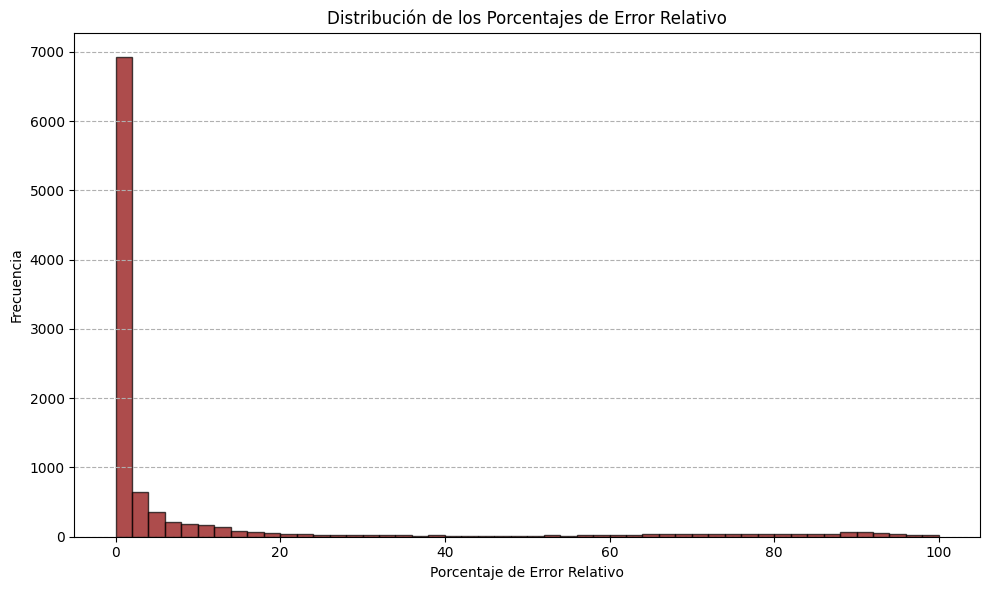

In [62]:
import matplotlib.pyplot as plt

# ...

# Muestra todos los porcentajes al final
# Calcula y muestra el promedio de los porcentajes
promedio = np.mean(porcentajes)
print(f"El promedio de los porcentajes es {promedio:.2f}%")

# Crea un histograma de los porcentajes
plt.figure(figsize=(10, 6))
plt.hist(porcentajes, bins=50, edgecolor='black', alpha=0.7, color = 'darkred')
plt.title('Distribución de los Porcentajes de Error Relativo')
plt.xlabel('Porcentaje de Error Relativo')
plt.ylabel('Frecuencia')
plt.grid(axis='y', linestyle='--')
plt.tight_layout()
plt.show()